# Lab 5: Linear Regression, Predicting House Prices

**Name:** Yusra Batool

**Student ID:** 023-24-0216

**Section:** G

**GitHub:** github.com/Yusra-Shah

**Kaggle:** yusrabatool

**Dataset:** House Prices - Advanced Regression Techniques

**Dataset Source:** Kaggle (kaggle.com/competitions/house-prices-advanced-regression-techniques)

## Part 1 : Dataset, Problem & Feature/Target Identification

In [12]:
# Task 1 — load and inspect
import pandas as pd
import numpy as np

train = pd.read_csv("train.csv")
print(train.shape)
print(train.info())
print(train.describe())

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [13]:
# Task 2 — select a manageable feature subset, split numerical/categorical
selected_features = [
    "GrLivArea", "OverallQual", "TotalBsmtSF", "GarageCars", "YearBuilt",
    "FullBath", "TotRmsAbvGrd", "LotArea",
    "Neighborhood", "HouseStyle", "KitchenQual"
]
df = train[selected_features + ["SalePrice"]].copy()
print(df.dtypes)

GrLivArea       int64
OverallQual     int64
TotalBsmtSF     int64
GarageCars      int64
YearBuilt       int64
FullBath        int64
TotRmsAbvGrd    int64
LotArea         int64
Neighborhood      str
HouseStyle        str
KitchenQual       str
SalePrice       int64
dtype: object


**Dependent variable:** SalePrice.

**Independent variables (numerical):** GrLivArea, OverallQual, TotalBsmtSF, GarageCars, YearBuilt, FullBath, TotRmsAbvGrd, LotArea.

**Independent variables (categorical):** Neighborhood, HouseStyle, KitchenQual.

**Why regression, not classification:** SalePrice is a continuous dollar amount, not a category, so we're predicting a number on an open-ended scale rather than choosing between a fixed set of labels. This changes evaluation completely, instead of accuracy or a confusion matrix, we need metrics like MAE, RMSE, and R² that measure how far off predictions are in actual price terms.

## Part 2 : Data Preparation & Train/Test Split

In [14]:
# Task 4 — encode categorical columns
from sklearn.model_selection import train_test_split

y = df["SalePrice"]
X = df.drop(columns=["SalePrice"])
categorical_cols = ["Neighborhood", "HouseStyle", "KitchenQual"]
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print(X.shape)

(1460, 42)


**Encoding justification:** All three categorical columns (Neighborhood, HouseStyle, KitchenQual) were one-hot encoded rather than manually mapped, since none of them have a natural single ordering that a plain 0/1/2 scale could represent honestly, especially Neighborhood with many unrelated categories. drop_first=True avoids redundant columns, since one category is always inferable from the rest being 0.

In [15]:
# Task 5 — confirm X is numeric with no missing values
print(X.isnull().sum().sum())
print(X.select_dtypes(exclude=[np.number, bool]).columns.tolist())

0
[]


In [16]:
# Task 6 — train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

X_train: (1168, 42) X_test: (292, 42)
y_train: (1168,) y_test: (292,)


## Part 3 : Linear Regression & Predictions

In [17]:
# Task 7-8 — train model, predict, compare actual vs predicted
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

comparison_table = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10].round(0)})
print(comparison_table)

   Actual  Predicted
0  154500   138291.0
1  325000   321811.0
2  115000   113453.0
3  159000   170581.0
4  315500   307301.0
5   75500    66676.0
6  311500   235616.0
7  146000   147090.0
8   84500    66376.0
9  135500   122849.0


**Prediction quality note:** Most predictions land within about 10,000-15,000 dollars of the actual price, but row 6 (actual 311,500, predicted 235,616) is off by about 76,000, showing the model can miss badly on individual houses even when it's accurate on average.

## Part 4 : Coefficients & Intercept

In [18]:
# Task 9 — extract intercept and coefficients
print("Intercept:", round(model.intercept_, 2))
coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_}).sort_values("Coefficient", ascending=False)
print(coef_table.to_string(index=False))

Intercept: -550414.1
             Feature   Coefficient
Neighborhood_NoRidge  76843.439365
Neighborhood_StoneBr  63713.267073
Neighborhood_NridgHt  56983.480105
Neighborhood_Veenker  54128.561562
Neighborhood_Crawfor  47435.336366
Neighborhood_ClearCr  41793.599217
Neighborhood_Somerst  30455.672489
 Neighborhood_Timber  26424.456557
Neighborhood_BrkSide  25377.766584
Neighborhood_CollgCr  22463.602686
Neighborhood_Gilbert  20651.773602
 Neighborhood_Sawyer  16355.843570
   HouseStyle_SFoyer  15585.660668
 Neighborhood_NWAmes  15377.086015
  Neighborhood_NAmes  14701.590068
 Neighborhood_IDOTRR  14696.315448
Neighborhood_SawyerW  14301.678452
         OverallQual  13598.553763
Neighborhood_Mitchel  13053.399806
  Neighborhood_SWISU  12478.988392
Neighborhood_NPkVill  12462.417958
   HouseStyle_1Story  11295.021447
          GarageCars  10601.200344
Neighborhood_OldTown   8097.834169
Neighborhood_MeadowV   7983.136029
     HouseStyle_SLvl   7503.006162
Neighborhood_Edwards   4717.901999

**Intercept interpretation:** The intercept (-$550,414) has no sensible real-world meaning on its own, since it represents the predicted price when every feature, including GrLivArea and LotArea, equals zero. No real house has zero living area, and every house belongs to exactly one neighborhood and quality category, so this "all zeros" case never occurs in reality. The intercept exists mathematically to anchor the line, not to describe an actual house.

## Part 5 : Residuals & Regression Metrics

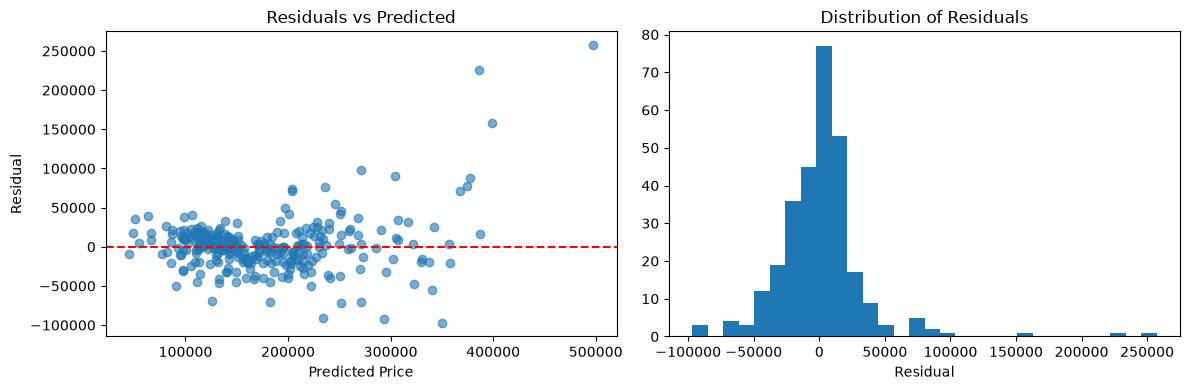

In [19]:
# Task 11 — residual plots
import matplotlib.pyplot as plt

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

axes[1].hist(residuals, bins=30)
axes[1].set_xlabel("Residual")
axes[1].set_title("Distribution of Residuals")
plt.tight_layout()
plt.show()

**Residual pattern:** Residuals are mostly scattered close to zero for lower and mid-range predicted prices, but the spread visibly widens for higher predicted prices, several of the largest positive residuals occur above $300,000 predicted. This is a pattern, not random noise, it means the model is less reliable for expensive houses, likely because there are fewer of them in the training data and their prices depend on factors (luxury finishes, unique architecture) not captured by this feature subset.

In [20]:
# Task 12 — MAE, MSE, RMSE, R2
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.4f}")

MAE:  21148.34
MSE:  1212283395.92
RMSE: 34817.86
R2:   0.8420


**What each metric tells you:** MAE says predictions are off by about $21,148 $ on average, easy to picture directly in dollars. MSE squares the errors before averaging, penalizing big misses harder, but the resulting number isn't interpretable on its own. RMSE undoes that squaring, giving back a dollar-scale number ($34,818) still sensitive to large errors, useful for comparing models. R² (0.842) says the model explains about 84% of the variation in house prices using just these 11 features.

**Which to show a non-technical stakeholder:** MAE. Saying "predictions are typically off by about $21,000" is immediately understandable without a stats background, while RMSE and R² need more explanation to interpret correctly.

## Part 6 : Training vs. Testing & Generalization

In [21]:
# Task 14 — train vs test comparison
y_train_pred = model.predict(X_train)

train_metrics = {
    "MAE": mean_absolute_error(y_train, y_train_pred),
    "MSE": mean_squared_error(y_train, y_train_pred),
    "RMSE": np.sqrt(mean_squared_error(y_train, y_train_pred)),
    "R2": r2_score(y_train, y_train_pred),
}
test_metrics = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

metrics_comparison = pd.DataFrame({"Train": train_metrics, "Test": test_metrics})
print(metrics_comparison)

             Train          Test
MAE   2.029536e+04  2.114834e+04
MSE   1.029279e+09  1.212283e+09
RMSE  3.208238e+04  3.481786e+04
R2    8.274339e-01  8.419515e-01


**Overfitting check:** There is no meaningful gap here, MAE and RMSE are within a few thousand dollars of each other between train and test, and test R² (0.842) is actually slightly higher than train R² (0.8274). This happens because the test set has more price variance by chance (higher SalePrice standard deviation), not because of any error. A large gap, high train performance with much worse test performance, would suggest overfitting. What we see instead is consistent performance on unseen data, suggesting the model generalizes well and isn't overfit, likely because Linear Regression with only 11 base features has limited capacity to memorize noise in the first place.

## Part 7 : Final Model Analysis, Conclusion & Kaggle Submission

**Task 16 most influential features:** Neighborhood_NoRidge (+76,843) and Neighborhood_StoneBr (+63,713) have the single largest coefficients in the entire model, larger than any numerical feature. However, coefficient size alone can be misleading when scales differ, GrLivArea's coefficient (49.81) looks tiny next to Neighborhood's, but GrLivArea ranges over thousands of square feet, so its total contribution to price is actually large too, just spread across a bigger numeric range. OverallQual (13,598.55 per point, on roughly a 1-10 scale) is arguably the most practically influential feature, since a realistic quality swing of 3-4 points moves price by $40,000-$50,000, a bigger real-world effect than switching neighborhoods for most houses.

**Task 17 final interpretation:** The model explains about 84% of the variation in house prices using just 11 selected features out of the 79 available, and is typically off by around $21,000 on the test set. R² and MAE together are the most useful metrics here, R² for an overall sense of fit, MAE for a plain-dollar sense of typical error size a stakeholder can act on. Neighborhood location has the single strongest effect on price, exceeding even overall quality or living area in raw coefficient size. Linear Regression's main limitation here is that it assumes each feature's effect is constant and additive, it can't capture diminishing returns on extra square footage or interactions between quality and neighborhood, and it's visibly less accurate on expensive houses, as the residual plot showed. With more time, I'd try Ridge or Lasso regression to handle correlation between features like GrLivArea and TotRmsAbvGrd, and would expand the feature set using some of the other 68 unused columns.

In [22]:
# Task 18 — build submission.csv from test.csv
test_raw = pd.read_csv("test.csv")
X_submit = test_raw[selected_features].copy()

# test.csv has a few missing values that train.csv didn't; fill using train statistics
X_submit["TotalBsmtSF"] = X_submit["TotalBsmtSF"].fillna(df["TotalBsmtSF"].median())
X_submit["GarageCars"] = X_submit["GarageCars"].fillna(df["GarageCars"].median())
X_submit["KitchenQual"] = X_submit["KitchenQual"].fillna(df["KitchenQual"].mode()[0])

X_submit_encoded = pd.get_dummies(X_submit, columns=categorical_cols, drop_first=True)
X_submit_encoded = X_submit_encoded.reindex(columns=X.columns, fill_value=0)

test_predictions = model.predict(X_submit_encoded)

submission = pd.DataFrame({"Id": test_raw["Id"], "SalePrice": test_predictions})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
print(submission.head())

(1459, 2)
     Id      SalePrice
0  1461  113554.496343
1  1462  161951.375226
2  1463  161053.643202
3  1464  182378.026156
4  1465  247959.409673


**Note on missing values:** test.csv (unlike train.csv) has a few missing values in TotalBsmtSF, GarageCars, and KitchenQual for this feature subset. These were filled using train.csv's median (numerical) or mode (categorical), not test.csv's own statistics, to avoid leaking information from the test set into preprocessing.

**Task 19  Kaggle leaderboard:** My submission scored 0.16675 (RMSE on log price), placing rank 2563 on the public leaderboard. Seeing my model measured against thousands of real submissions was a good reality check, my simple 11-feature Linear Regression landed right in the expected range for a basic model, close to other similarly-scoped submissions on the board (Walker Hawley at 0.16670, skippies_11 at 0.16678), confirming the model is reasonable without heavy feature engineering.